# AI Bike Fit: laboratorio inicial

Esta notebook valida el núcleo técnico sobre las anotaciones reales del repositorio antes de construir la aplicación: carga de CVAT, geometría 2D, métricas de movimiento, reglas expertas y repetibilidad.

**Datos:** `data/default/frame_XXXXXX.PNG` y `data/annotations.xml`. El XML contiene esqueletos anotados por frame para 20 tareas de vídeo. Las anotaciones son la referencia de validación; todavía no son predicciones de MediaPipe.

**Alcance:** no es una herramienta clínica ni sustituye una revisión profesional. La primera pregunta experimental es si los landmarks anotados permiten obtener métricas biomecánicas estables y visualmente plausibles.

**Hipótesis:** una pose 2D suficientemente estable permite calcular métricas consistentes por frame y comparar lados; las reglas deben devolver evidencia y confianza ajustada por la calidad y la visibilidad de las anotaciones.

## 1. Configurar entorno y dependencias

Fijamos la semilla para que los datos sintéticos y el ruido sean reproducibles.

In [2]:
from __future__ import annotations

import math
import platform
import time
import xml.etree.ElementTree as ET
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

SEED = 42
RNG = np.random.default_rng(SEED)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
IMAGE_DIR = DATA_DIR / "default"
ANNOTATIONS_FILE = DATA_DIR / "annotations.xml"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

print(f"Python: {platform.python_version()}")
print(f"NumPy: {np.__version__}")
print(f"Datos: {DATA_DIR}")
print(f"Imágenes: {len(list(IMAGE_DIR.glob('frame_*.PNG')))}")
print(f"XML: {ANNOTATIONS_FILE.exists()}")
print(f"Semilla: {SEED}")

Python: 3.13.13
NumPy: 2.5.3
Datos: /Users/pol.serra/src-out/bikeFit/data
Imágenes: 480
XML: True
Semilla: 42


## 2. Cargar anotaciones CVAT

El XML usa un `<track>` por vídeo y un `<skeleton>` por frame. Cada esqueleto contiene 14 puntos anatómicos con coordenadas en píxeles y flags `outside`/`occluded`. Como el export no incluye el nombre de archivo de cada frame, usamos el orden de las tareas y sus 24 frames para mapearlos a `frame_000000.PNG` ... `frame_000479.PNG`.

In [4]:
LANDMARKS = [
    "shoulder", "elbow", "wrist", "hip", "knee", "ankle", "foot_index"
]
SIDES = ["left", "right"]


def parse_cvat_annotations(xml_path: Path, image_dir: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    root = ET.parse(xml_path).getroot()
    tasks = list(root.findall("./meta/project/tasks/task"))
    task_order = {task.findtext("id"): index for index, task in enumerate(tasks)}
    task_info = {
        task.findtext("id"): {
            "source": task.findtext("source"),
            "width": int(task.findtext("original_size/width")),
            "height": int(task.findtext("original_size/height")),
            "size": int(task.findtext("size")),
        }
        for task in tasks
    }

    rows = []
    for track in root.findall("track"):
        if track.get("label") != "person":
            continue
        task_id = track.get("task_id")
        task_index = task_order[task_id]
        task_size = task_info[task_id]["size"]
        for skeleton in track.findall("skeleton"):
            global_frame = int(skeleton.get("frame"))
            local_frame = global_frame - task_index * task_size
            row = {
                "task_id": task_id,
                "task_index": task_index,
                "frame": local_frame,
                "global_frame": global_frame,
                "image_path": image_dir / f"frame_{global_frame:06d}.PNG",
                "width": task_info[task_id]["width"],
                "height": task_info[task_id]["height"],
                "source": task_info[task_id]["source"],
            }
            for point in skeleton.findall("points"):
                label = point.get("label")
                x, y = (float(value) for value in point.get("points").split(","))
                row[f"{label}_x"] = x
                row[f"{label}_y"] = y
                row[f"{label}_occluded"] = point.get("occluded") == "1"
                row[f"{label}_outside"] = point.get("outside") == "1"
            rows.append(row)

    frames = pd.DataFrame(rows).sort_values(["task_index", "frame"]).reset_index(drop=True)
    task_summary = (
        frames.groupby(["task_id", "task_index", "source"], as_index=False)
        .agg(frames=("frame", "count"), width=("width", "first"), height=("height", "first"))
    )
    return frames, task_summary


frames, task_summary = parse_cvat_annotations(ANNOTATIONS_FILE, IMAGE_DIR)
print(f"Frames anotados: {len(frames)}")
print(f"Tareas de vídeo: {len(task_summary)}")
print(f"Landmarks por frame: {len([column for column in frames.columns if column.endswith('_x')])}")
print(f"Imágenes asociadas existentes: {frames['image_path'].map(Path.exists).all()}")
display(task_summary.head())

Frames anotados: 480
Tareas de vídeo: 20
Landmarks por frame: 14
Imágenes asociadas existentes: True


,task_id,task_index,source,frames,width,height
0,1798170,0,01_unblurred.mp4,24,1080,1920
1,1798171,1,02_unblurred.mp4,24,1080,1920
2,1798174,2,03_unblurred.mp4,24,720,720
3,1798175,3,04_unblurred.mp4,24,1920,1080
4,1798176,4,05_unblurred.mp4,24,1080,1920


## 3. Elegir vídeo y foto a analizar

El dataset contiene los vídeos como secuencias de imágenes anotadas. Selecciona el vídeo de origen y el frame; el frame elegido se utilizará en la visualización de pose y ángulos.

In [5]:
import ipywidgets as widgets
from IPython.display import display

video_options = sorted(frames["source"].unique())
source_selector = widgets.Dropdown(
    options=video_options,
    value=video_options[0],
    description="Vídeo:",
    layout=widgets.Layout(width="420px"),
)
frame_selector = widgets.IntSlider(
    value=0,
    min=0,
    max=int(frames.loc[frames["source"] == video_options[0], "frame"].max()),
    step=1,
    description="Frame:",
    continuous_update=False,
    layout=widgets.Layout(width="420px"),
)
show_button = widgets.Button(
    description="Mostrar frame",
    button_style="primary",
    icon="image",
)
selection_output = widgets.Output()


def get_selected_row() -> pd.Series | None:
    selected_rows = frames[
        (frames["source"] == source_selector.value)
        & (frames["frame"] == frame_selector.value)
    ]
    if selected_rows.empty:
        return None
    return selected_rows.iloc[0]


def update_frame_range(change=None):
    source_frames = frames.loc[frames["source"] == source_selector.value, "frame"]
    frame_selector.max = int(source_frames.max())
    frame_selector.value = int(source_frames.min())


def show_selected_frame(change=None):
    global selected_row
    selected_row = get_selected_row()
    if selected_row is None:
        return
    with selection_output:
        selection_output.clear_output(wait=True)
        print(f"Vídeo: {selected_row['source']}")
        print(f"Frame: {selected_row['frame']} · {selected_row['image_path'].name}")
        print(f"Ruta: {selected_row['image_path']}")
        print(f"Existe: {selected_row['image_path'].exists()}")
        if "plot_annotated_frame" in globals():
            plot_annotated_frame(selected_row)
        else:
            display(Image.open(selected_row["image_path"]))


source_selector.observe(update_frame_range, names="value")
source_selector.observe(show_selected_frame, names="value")
frame_selector.observe(show_selected_frame, names="value")
show_button.on_click(show_selected_frame)
selected_row = frames.iloc[0]
show_selected_frame()
display(widgets.VBox([
    widgets.HTML("<b>Selecciona un vídeo y un frame:</b>"),
    source_selector,
    frame_selector,
    show_button,
    selection_output,
]))

## 3. Inspección visual de las anotaciones

Antes de calcular ángulos, revisamos que el mapeo imagen/XML sea correcto y que los puntos caigan sobre el ciclista.

Existe la imagen asociada: True


NameError: name 'angle_at' is not defined

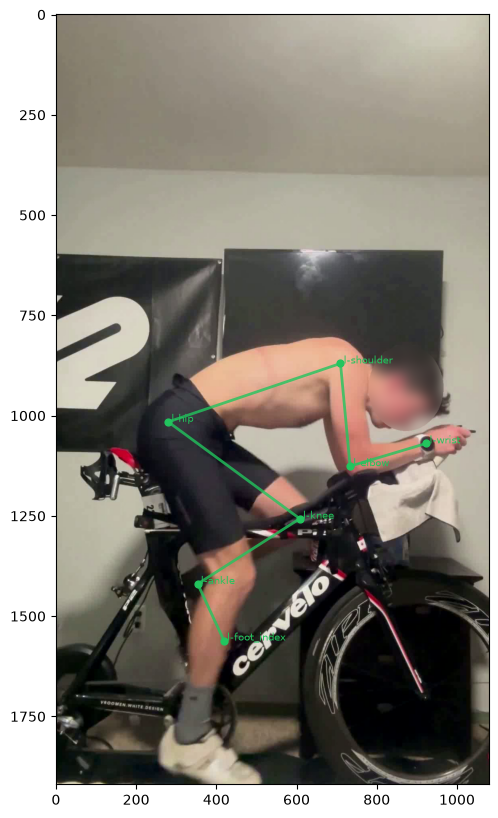

In [6]:
def plot_annotated_frame(frame_row: pd.Series) -> None:
    image = Image.open(frame_row["image_path"])
    figure, axis = plt.subplots(figsize=(7, 10))
    axis.imshow(image)
    colors = {"left": "#22c55e", "right": "#ef4444"}
    metric_specs = {
        "knee": ("hip", "knee", "ankle"),
        "hip": ("shoulder", "hip", "knee"),
        "ankle": ("knee", "ankle", "foot_index"),
        "elbow": ("shoulder", "elbow", "wrist"),
    }

    for side in SIDES:
        color = colors[side]
        for landmark in LANDMARKS:
            x = frame_row.get(f"{side}_{landmark}_x")
            y = frame_row.get(f"{side}_{landmark}_y")
            if pd.notna(x) and pd.notna(y):
                axis.scatter(x, y, s=24, color=color, zorder=3)
                axis.text(x + 8, y, f"{side[0]}-{landmark}", color=color, fontsize=7, zorder=4)

        segments = {
            ("shoulder", "elbow"), ("elbow", "wrist"),
            ("shoulder", "hip"), ("hip", "knee"),
            ("knee", "ankle"), ("ankle", "foot_index"),
        }
        for first, second in segments:
            axis.plot(
                [frame_row[f"{side}_{first}_x"], frame_row[f"{side}_{second}_x"]],
                [frame_row[f"{side}_{first}_y"], frame_row[f"{side}_{second}_y"]],
                color=color,
                linewidth=2,
                alpha=0.8,
                zorder=2,
            )

        for metric_name, (first, vertex, last) in metric_specs.items():
            angle = angle_at(frame_row, side, first, vertex, last)
            vertex_x = frame_row[f"{side}_{vertex}_x"]
            vertex_y = frame_row[f"{side}_{vertex}_y"]
            axis.text(
                vertex_x + 12,
                vertex_y - 12,
                f"{metric_name}: {angle:.1f}°",
                color="white",
                fontsize=8,
                weight="bold",
                bbox={"facecolor": color, "alpha": 0.8, "pad": 2, "edgecolor": "none"},
                zorder=5,
            )

    axis.set_title(f"{frame_row['source']} · frame {frame_row['frame']} · {frame_row['image_path'].name}")
    axis.axis("off")
    plt.tight_layout()


print(f"Existe la imagen asociada: {selected_row['image_path'].exists()}")
plot_annotated_frame(selected_row)

## 4. Métricas biomecánicas 2D

Los ángulos se calculan con tres puntos y son invariantes a la escala de la imagen. En esta fase medimos la señal anotada, no inferimos todavía rangos clínicos universales.

In [ ]:
def point(row: pd.Series, side: str, landmark: str) -> np.ndarray:
    return np.array([row[f"{side}_{landmark}_x"], row[f"{side}_{landmark}_y"]], dtype=float)


def angle_at(row: pd.Series, side: str, first: str, vertex: str, last: str) -> float:
    first_point = point(row, side, first)
    vertex_point = point(row, side, vertex)
    last_point = point(row, side, last)
    first_vector = first_point - vertex_point
    last_vector = last_point - vertex_point
    cosine = np.dot(first_vector, last_vector) / (np.linalg.norm(first_vector) * np.linalg.norm(last_vector))
    return float(np.degrees(np.arccos(np.clip(cosine, -1.0, 1.0))))


def calculate_metrics(frame_table: pd.DataFrame) -> pd.DataFrame:
    result = frame_table.copy()
    for side in SIDES:
        result[f"{side}_knee_angle"] = result.apply(
            angle_at, axis=1, side=side, first="hip", vertex="knee", last="ankle"
        )
        result[f"{side}_hip_angle"] = result.apply(
            angle_at, axis=1, side=side, first="shoulder", vertex="hip", last="knee"
        )
        result[f"{side}_ankle_angle"] = result.apply(
            angle_at, axis=1, side=side, first="knee", vertex="ankle", last="foot_index"
        )
        result[f"{side}_elbow_angle"] = result.apply(
            angle_at, axis=1, side=side, first="shoulder", vertex="elbow", last="wrist"
        )
    result["pelvis_y_spread"] = (result["left_hip_y"] - result["right_hip_y"]).abs()
    result["hip_visibility"] = (~result["left_hip_occluded"]).astype(int) + (~result["right_hip_occluded"]).astype(int)
    result["visible_landmark_ratio"] = result.apply(
        lambda row: np.mean([
            not row[f"{side}_{landmark}_outside"]
            for side in SIDES for landmark in LANDMARKS
        ]), axis=1
    )
    return result


metrics = calculate_metrics(frames)
metric_columns = [
    "left_knee_angle", "right_knee_angle", "left_hip_angle", "right_hip_angle",
    "left_ankle_angle", "right_ankle_angle", "left_elbow_angle", "right_elbow_angle",
    "pelvis_y_spread", "visible_landmark_ratio",
]
display(metrics[metric_columns].describe().round(2))

,left_knee_angle,right_knee_angle,left_hip_angle,right_hip_angle,left_ankle_angle,right_ankle_angle,left_elbow_angle,right_elbow_angle,pelvis_y_spread,visible_landmark_ratio
count,480.00,480.00,480.00,480.00,480.00,480.00,480.00,480.00,480.00,480.0
mean,97.03,98.25,77.35,79.55,95.07,97.61,140.70,139.60,6.28,1.0
std,25.69,25.42,20.42,20.28,12.16,13.50,31.90,31.61,6.42,0.0
min,47.20,52.97,30.04,34.46,57.38,66.38,74.45,71.34,0.12,1.0
25%,72.58,75.09,62.05,65.84,87.11,87.62,112.59,108.47,1.35,1.0
50%,95.39,96.83,76.61,78.30,95.90,97.42,154.81,154.84,3.86,1.0
75%,119.47,120.36,91.70,94.82,103.41,107.28,163.34,159.69,8.91,1.0
max,150.99,154.23,139.05,142.92,133.47,134.64,174.38,178.64,25.92,1.0


## 5. Primera comprobación de reglas

Estas reglas son exploratorias y no deben interpretarse como recomendación clínica. Sirven para comprobar que el resultado puede expresar diagnóstico, evidencia y confianza de forma estructurada.

In [ ]:
def diagnose_frame(row: pd.Series, side: str = "right") -> list[dict]:
    diagnoses = []
    knee_angle = row[f"{side}_knee_angle"]
    if knee_angle < 145:
        diagnoses.append({
            "code": "KNEE_EXTENSION_LOW",
            "title": "Extensión de rodilla reducida",
            "confidence": 0.70,
            "evidence": {"knee_angle_deg": round(knee_angle, 1)},
            "action": "Revisar si el sillín está bajo",
        })
    elif knee_angle > 155:
        diagnoses.append({
            "code": "KNEE_EXTENSION_HIGH",
            "title": "Extensión de rodilla elevada",
            "confidence": 0.70,
            "evidence": {"knee_angle_deg": round(knee_angle, 1)},
            "action": "Revisar si el sillín está alto",
        })
    if row["pelvis_y_spread"] > 18:
        diagnoses.append({
            "code": "PELVIS_ROCKING_CANDIDATE",
            "title": "Posible oscilación de pelvis",
            "confidence": 0.55,
            "evidence": {"hip_vertical_difference_px": round(row["pelvis_y_spread"], 1)},
            "action": "Revisar estabilidad de pelvis y altura del sillín",
        })
    return diagnoses


rule_results = []
for _, row in metrics.iterrows():
    for diagnosis in diagnose_frame(row):
        rule_results.append({
            "source": row["source"],
            "frame": row["frame"],
            **diagnosis,
        })

rule_results = pd.DataFrame(rule_results)
if rule_results.empty:
    print("No se activaron reglas exploratorias en este subconjunto.")
else:
    display(rule_results.groupby(["code", "title"], as_index=False).agg(
        frames=("frame", "count"), mean_confidence=("confidence", "mean")
    ).round(2))

,code,title,frames,mean_confidence
0,KNEE_EXTENSION_LOW,Extensión de rodilla reducida,473,0.70
1,PELVIS_ROCKING_CANDIDATE,Posible oscilación de pelvis,35,0.55


## 6. Estabilidad y exportación

Agregamos un resumen por vídeo. La variación intra-vídeo ayuda a distinguir una señal biomecánica real de una anotación o detección inestable.

In [ ]:
video_summary = (
    metrics.groupby(["task_id", "source"], as_index=False)
    .agg(
        frames=("frame", "count"),
        knee_left_mean=("left_knee_angle", "mean"),
        knee_left_std=("left_knee_angle", "std"),
        knee_right_mean=("right_knee_angle", "mean"),
        knee_right_std=("right_knee_angle", "std"),
        pelvis_spread_mean_px=("pelvis_y_spread", "mean"),
        pelvis_spread_max_px=("pelvis_y_spread", "max"),
        visible_landmark_ratio=("visible_landmark_ratio", "mean"),
    )
)
video_summary["knee_side_difference_mean"] = (
    video_summary["knee_left_mean"] - video_summary["knee_right_mean"]
).abs()
video_summary = video_summary.sort_values("source")
display(video_summary.round(2))

metrics.to_csv(OUTPUT_DIR / "annotated_frame_metrics.csv", index=False)
video_summary.to_csv(OUTPUT_DIR / "annotated_video_summary.csv", index=False)
print(f"Exportados: {OUTPUT_DIR / 'annotated_frame_metrics.csv'}")
print(f"Exportados: {OUTPUT_DIR / 'annotated_video_summary.csv'}")

,task_id,source,frames,knee_left_mean,knee_left_std,knee_right_mean,knee_right_std,pelvis_spread_mean_px,pelvis_spread_max_px,visible_landmark_ratio,knee_side_difference_mean
0,1798170,01_unblurred.mp4,24,100.89,27.13,102.16,25.05,11.80,16.00,1.0,1.26
1,1798171,02_unblurred.mp4,24,94.69,24.72,104.67,24.87,25.02,25.92,1.0,9.98
2,1798174,03_unblurred.mp4,24,94.65,23.24,92.26,23.83,2.99,3.70,1.0,2.39
3,1798175,04_unblurred.mp4,24,92.29,27.36,102.75,28.33,11.55,18.98,1.0,10.46
4,1798176,05_unblurred.mp4,24,107.38,27.63,105.52,32.17,16.91,20.61,1.0,1.86
5,1798177,06_unblurred.mp4,24,100.81,25.94,98.42,20.61,4.57,5.91,1.0,2.39
6,1798179,07_unblurred.mp4,24,94.34,25.74,95.90,25.57,5.57,11.45,1.0,1.56
7,1798180,08_unblurred.mp4,24,100.69,25.38,103.87,25.47,0.57,1.29,1.0,3.18
8,1798182,09_unblurred.mp4,24,102.24,25.85,100.51,22.44,1.14,1.73,1.0,1.73
9,1798183,10_unblurred.mp4,24,94.72,25.07,101.41,25.92,2.06,6.14,1.0,6.69


Exportados: /Users/pol.serra/src-out/bikeFit/outputs/annotated_frame_metrics.csv
Exportados: /Users/pol.serra/src-out/bikeFit/outputs/annotated_video_summary.csv


## 7. Criterio de decisión

Este experimento será una señal positiva si:

- Las imágenes asociadas al XML contienen los landmarks en la posición esperada.
- Los ángulos no presentan saltos inexplicables entre frames consecutivos.
- La variación de rodilla y pelvis es suficiente para distinguir fases de la pedalada.
- Los resultados son razonablemente consistentes entre los dos lados cuando ambos son visibles.

**Siguiente paso:** comparar estas métricas de referencia con la salida de MediaPipe Pose sobre las mismas imágenes. La diferencia entre anotación manual y predicción permitirá medir el error del detector antes de diseñar reglas más ambiciosas.

## 8. Tools de análisis para un LLM

Estas funciones deterministas son las que expondríamos a un modelo mediante
*function-calling*. El reparto de responsabilidades es deliberado:

- **Los tools calculan** (fase de pedalada, ángulos, normalización, estabilidad).
- **El LLM interpreta y redacta tips**, pero no hace trigonometría ni inventa umbrales.
- Cada tool devuelve `value + quality/confidence + evidence`, nunca un número suelto.

Reglas para el modelo:

1. Empezar siempre por `assess_data_quality`; si la calidad es baja, bajar confianza o no diagnosticar.
2. No usar un ángulo sin pasar por `detect_pedal_cycles` (medir en la fase correcta).
3. Los rangos solo salen de `get_reference_ranges`; está prohibido inventarlos.
4. Todo tip debe citar evidencia y confianza, y recordar que no es consejo clínico.


In [ ]:
from typing import Any

# Rangos exploratorios centralizados (ver docs/ANALISIS-DE-RESULTADOS.md).
# El LLM NO debe inventar cifras: solo puede leerlas desde aquí.
REFERENCE_RANGES: dict[str, dict[str, dict[str, Any]]] = {
    "knee_angle": {
        "road": {
            "low": 140.0, "high": 150.0, "unit": "grados (ángulo interno)",
            "phase": "max_extension",
            "note": "Holmes 25-35° de flexión estática ~ 145-155° interno; dinámico ~140-150°.",
            "source": "cyclingweekly.com set-saddle-height / Holmes",
        },
    },
    "hip_angle": {
        "tt": {
            "low": 40.0, "high": 55.0, "unit": "grados (mínimo de cadera)",
            "phase": "min_hip",
            "note": "~50° flexibilidad media, ~45° eventos cortos, ~40° muy flexibles.",
            "source": "bikedynamics.co.uk FitGuideTT",
        },
    },
    "pelvis_rock_norm": {
        "road": {
            "low": 0.0, "high": 0.12, "unit": "fracción de longitud de fémur",
            "phase": "cycle",
            "note": "HEURÍSTICO sin base publicada; sustituye al umbral fijo en px. Calibrar con datos.",
            "source": "propio (pendiente de validación)",
        },
    },
}


def _py(value: Any) -> Any:
    """Convierte tipos numpy/pandas a nativos para respuestas JSON-serializables."""
    if isinstance(value, (np.floating,)):
        return None if np.isnan(value) else round(float(value), 2)
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, float):
        return None if math.isnan(value) else round(value, 2)
    return value


def _source_frames(source: str) -> pd.DataFrame:
    """Frames de un vídeo ordenados temporalmente."""
    subset = metrics[metrics["source"] == source].sort_values("frame")
    if subset.empty:
        raise ValueError(f"Vídeo desconocido: {source!r}")
    return subset


def _local_peaks(values: np.ndarray, min_distance: int = 2, prominence: float = 3.0) -> list[int]:
    """Detector de máximos locales sin dependencias externas (datos cortos)."""
    y = np.asarray(values, dtype=float)
    n = len(y)
    if n == 0:
        return []
    baseline = np.nanmedian(y)
    candidates = [
        i for i in range(n)
        if y[i] >= (y[i - 1] if i > 0 else -np.inf)
        and y[i] >= (y[i + 1] if i < n - 1 else -np.inf)
        and y[i] >= baseline + prominence
    ]
    selected: list[int] = []
    for i in candidates:
        if selected and i - selected[-1] < min_distance:
            if y[i] > y[selected[-1]]:
                selected[-1] = i
            continue
        selected.append(i)
    return selected


def get_available_videos() -> list[dict[str, Any]]:
    """Lista los vídeos analizables con su tamaño y resolución."""
    summary = (
        metrics.groupby("source", as_index=False)
        .agg(frames=("frame", "count"), width=("width", "first"), height=("height", "first"))
        .sort_values("source")
    )
    return [
        {"source": row["source"], "frames": int(row["frames"]),
         "width": int(row["width"]), "height": int(row["height"])}
        for _, row in summary.iterrows()
    ]


def assess_data_quality(source: str, side: str = "right") -> dict[str, Any]:
    """Puerta de entrada: visibilidad de landmarks clave antes de diagnosticar."""
    subset = _source_frames(source)
    key_landmarks = ["hip", "knee", "ankle"]
    occluded = {
        lm: _py((subset[f"{side}_{lm}_occluded"]).mean()) for lm in key_landmarks
    }
    outside = {
        lm: _py((subset[f"{side}_{lm}_outside"]).mean()) for lm in key_landmarks
    }
    visible_ratio = _py(subset["visible_landmark_ratio"].mean())
    quality_score = float(np.clip(
        (visible_ratio or 0.0) - np.mean(list(outside.values())), 0.0, 1.0
    ))
    return {
        "source": source,
        "side": side,
        "frames": int(len(subset)),
        "visible_landmark_ratio": visible_ratio,
        "occluded_fraction": occluded,
        "outside_fraction": outside,
        "quality_score": round(quality_score, 2),
        "reliable": quality_score >= 0.7,
    }


def detect_pedal_cycles(source: str, side: str = "right") -> dict[str, Any]:
    """Detecta fases del ciclo: máxima extensión (BDC) y mínima (TDC) de rodilla."""
    subset = _source_frames(source)
    knee = subset[f"{side}_knee_angle"].to_numpy()
    frame_ids = subset["frame"].to_numpy()
    extension_idx = _local_peaks(knee, min_distance=2, prominence=3.0)
    flexion_idx = _local_peaks(-knee, min_distance=2, prominence=3.0)
    global_max = int(np.argmax(knee)) if len(knee) else None
    return {
        "source": source,
        "side": side,
        "cycles_detected": len(extension_idx),
        "max_extension_frames": [int(frame_ids[i]) for i in extension_idx],
        "min_extension_frames": [int(frame_ids[i]) for i in flexion_idx],
        "primary_max_extension_frame": int(frame_ids[global_max]) if global_max is not None else None,
        "primary_knee_angle": _py(knee[global_max]) if global_max is not None else None,
    }


In [ ]:
def _resolve_frame(source: str, side: str, frame: int | None, phase: str) -> pd.Series:
    """Selecciona el frame pedido o el representativo de una fase del ciclo."""
    subset = _source_frames(source)
    if frame is not None:
        match = subset[subset["frame"] == frame]
        if match.empty:
            raise ValueError(f"Frame {frame} no existe en {source!r}")
        return match.iloc[0]
    if phase == "max_extension":
        return subset.loc[subset[f"{side}_knee_angle"].idxmax()]
    if phase == "min_extension":
        return subset.loc[subset[f"{side}_knee_angle"].idxmin()]
    if phase == "min_hip":
        return subset.loc[subset[f"{side}_hip_angle"].idxmin()]
    return subset.iloc[0]


def get_joint_angles(
    source: str, side: str = "right", frame: int | None = None, phase: str = "max_extension"
) -> dict[str, Any]:
    """Ángulos articulares en el frame o fase indicada, con visibilidad por articulación."""
    row = _resolve_frame(source, side, frame, phase)
    joints = {
        "knee": ("hip", "knee", "ankle"),
        "hip": ("shoulder", "hip", "knee"),
        "ankle": ("knee", "ankle", "foot_index"),
        "elbow": ("shoulder", "elbow", "wrist"),
    }
    angles = {name: _py(row[f"{side}_{name}_angle"]) for name in joints}
    visibility = {
        name: not bool(row.get(f"{side}_{vertex}_outside", False))
        for name, (_, vertex, _) in joints.items()
    }
    return {
        "source": source,
        "side": side,
        "frame": int(row["frame"]),
        "phase": phase if frame is None else "explicit",
        "angles_deg": angles,
        "vertex_visible": visibility,
    }


def get_normalized_pelvis_rock(source: str) -> dict[str, Any]:
    """Oscilación de pelvis normalizada por longitud de fémur (comparable entre vídeos)."""
    subset = _source_frames(source)
    femur_px = []
    for side in SIDES:
        dx = subset[f"{side}_hip_x"] - subset[f"{side}_knee_x"]
        dy = subset[f"{side}_hip_y"] - subset[f"{side}_knee_y"]
        femur_px.append(np.hypot(dx, dy))
    femur_reference = float(np.nanmean(np.concatenate([f.to_numpy() for f in femur_px])))
    spread_px = subset["pelvis_y_spread"]
    normalized = spread_px / femur_reference if femur_reference else spread_px * np.nan
    return {
        "source": source,
        "femur_reference_px": round(femur_reference, 1),
        "pelvis_rock_px_mean": _py(spread_px.mean()),
        "pelvis_rock_px_max": _py(spread_px.max()),
        "pelvis_rock_norm_mean": _py(normalized.mean()),
        "pelvis_rock_norm_max": _py(normalized.max()),
    }


def get_temporal_stability(source: str, side: str = "right") -> dict[str, Any]:
    """Estabilidad temporal: dispersión y saltos entre frames consecutivos."""
    subset = _source_frames(source)
    result: dict[str, Any] = {"source": source, "side": side, "frames": int(len(subset))}
    for name in ["knee", "hip", "ankle"]:
        series = subset[f"{side}_{name}_angle"]
        jumps = series.diff().abs()
        result[name] = {
            "mean": _py(series.mean()),
            "std": _py(series.std()),
            "max_frame_to_frame_jump": _py(jumps.max()),
        }
    return result


def compare_sides(source: str) -> dict[str, Any]:
    """Diferencia izquierda/derecha por métrica cuando ambos lados son visibles."""
    subset = _source_frames(source)
    result: dict[str, Any] = {"source": source}
    for name in ["knee", "hip", "ankle", "elbow"]:
        left = subset[f"left_{name}_angle"].mean()
        right = subset[f"right_{name}_angle"].mean()
        result[name] = {
            "left_mean": _py(left),
            "right_mean": _py(right),
            "abs_difference": _py(abs(left - right)),
        }
    return result


In [ ]:
def get_reference_ranges(metric: str, discipline: str = "road") -> dict[str, Any]:
    """Única fuente de rangos exploratorios; el LLM debe leerlos de aquí."""
    by_discipline = REFERENCE_RANGES.get(metric)
    if by_discipline is None:
        return {"metric": metric, "available_metrics": sorted(REFERENCE_RANGES)}
    reference = by_discipline.get(discipline) or next(iter(by_discipline.values()))
    return {"metric": metric, "discipline": discipline, **reference}


def evaluate_rule(
    metric: str, value: float, discipline: str = "road", quality_score: float = 1.0
) -> dict[str, Any]:
    """Evalúa un valor ya medido contra su rango y modula la confianza por calidad."""
    reference = get_reference_ranges(metric, discipline)
    low, high = reference.get("low"), reference.get("high")
    if value is None or low is None or high is None:
        return {"metric": metric, "status": "unknown", "confidence": 0.0,
                "reason": "valor o rango no disponible"}

    if value < low:
        status, hypothesis, action = "low", "por debajo del rango", "revisar posible sillín bajo / configuración baja"
    elif value > high:
        status, hypothesis, action = "high", "por encima del rango", "revisar posible sillín alto / configuración alta"
    else:
        status, hypothesis, action = "ok", "dentro del rango exploratorio", "sin ajuste sugerido"

    distance = 0.0 if status == "ok" else min(abs(value - low), abs(value - high))
    base_confidence = 0.75 if status != "ok" else 0.6
    confidence = round(float(np.clip(base_confidence * quality_score, 0.0, 0.9)), 2)
    return {
        "metric": metric, "discipline": discipline, "value": _py(value),
        "range": [low, high], "status": status, "hypothesis": hypothesis,
        "action": action, "deviation_deg": round(distance, 1),
        "confidence": confidence, "note": reference.get("note"),
        "disclaimer": "Orientativo, no es consejo clínico.",
    }


def analyze_video(source: str, side: str = "right", discipline: str = "road") -> dict[str, Any]:
    """Orquesta los tools y devuelve evidencia estructurada para que el LLM redacte tips."""
    quality = assess_data_quality(source, side)
    cycles = detect_pedal_cycles(source, side)
    angles = get_joint_angles(source, side, phase="max_extension")
    pelvis = get_normalized_pelvis_rock(source)
    stability = get_temporal_stability(source, side)
    sides = compare_sides(source)

    q = quality["quality_score"]
    findings = [
        evaluate_rule("knee_angle", angles["angles_deg"]["knee"], discipline, q),
        evaluate_rule("pelvis_rock_norm", pelvis["pelvis_rock_norm_mean"], discipline, q),
    ]
    return {
        "source": source, "side": side, "discipline": discipline,
        "data_quality": quality, "phase": cycles, "angles": angles,
        "pelvis_rock": pelvis, "stability": stability, "side_comparison": sides,
        "findings": [f for f in findings if f["status"] != "unknown"],
    }


# Registro para conectar a function-calling: nombre -> (callable, descripción).
TOOLS = {
    "get_available_videos": (get_available_videos, "Lista vídeos analizables."),
    "assess_data_quality": (assess_data_quality, "Visibilidad de landmarks antes de diagnosticar."),
    "detect_pedal_cycles": (detect_pedal_cycles, "Fases del ciclo (máxima/mínima extensión)."),
    "get_joint_angles": (get_joint_angles, "Ángulos articulares por fase o frame."),
    "get_normalized_pelvis_rock": (get_normalized_pelvis_rock, "Oscilación de pelvis normalizada."),
    "get_temporal_stability": (get_temporal_stability, "Dispersión y saltos temporales."),
    "compare_sides": (compare_sides, "Diferencia izquierda/derecha."),
    "get_reference_ranges": (get_reference_ranges, "Rangos exploratorios centralizados."),
    "evaluate_rule": (evaluate_rule, "Evalúa un valor contra su rango con confianza."),
    "analyze_video": (analyze_video, "Orquesta todos los tools y reúne la evidencia."),
}

print(f"Tools disponibles para el LLM: {len(TOOLS)}")
for name, (_, description) in TOOLS.items():
    print(f"  - {name}: {description}")

# Demo end-to-end sobre el primer vídeo.
import json

demo_source = get_available_videos()[0]["source"]
demo_report = analyze_video(demo_source, side="right")
print(f"\nInforme de evidencia para {demo_source!r}:")
print(json.dumps(demo_report["findings"], indent=2, ensure_ascii=False))


Tools disponibles para el LLM: 10
  - get_available_videos: Lista vídeos analizables.
  - assess_data_quality: Visibilidad de landmarks antes de diagnosticar.
  - detect_pedal_cycles: Fases del ciclo (máxima/mínima extensión).
  - get_joint_angles: Ángulos articulares por fase o frame.
  - get_normalized_pelvis_rock: Oscilación de pelvis normalizada.
  - get_temporal_stability: Dispersión y saltos temporales.
  - compare_sides: Diferencia izquierda/derecha.
  - get_reference_ranges: Rangos exploratorios centralizados.
  - evaluate_rule: Evalúa un valor contra su rango con confianza.
  - analyze_video: Orquesta todos los tools y reúne la evidencia.

Informe de evidencia para '01_unblurred.mp4':
[
  {
    "metric": "knee_angle",
    "discipline": "road",
    "value": 138.56,
    "range": [
      140.0,
      150.0
    ],
    "status": "low",
    "hypothesis": "por debajo del rango",
    "action": "revisar posible sillín bajo / configuración baja",
    "deviation_deg": 1.4,
    "confidenc

## 9. Inferencia con API de pose (Ultralytics)

Hasta ahora las métricas usaban las anotaciones manuales (CVAT). Aquí obtenemos la
pose con un **detector real vía API**, sin ejecutar YOLO en local, y comparamos su
salida con la anotación del mismo frame.

### Requisitos (los configura la persona usuaria, no van en el código)

La Inference API de Ultralytics usa un **endpoint dedicado** que se despliega en su
Platform. Antes de ejecutar, exporta dos variables de entorno y reinicia el kernel:

```bash
export ULTRALYTICS_ENDPOINT_URL="https://<tu-deployment>.run.app/predict"
export ULTRALYTICS_API_KEY="<tu-api-key>"
```

Notas:

- El modelo desplegado debe ser de **pose** (YOLO11/YOLOv8-pose, keypoints COCO-17).
- COCO-17 **no** incluye `foot_index`, así que el ángulo de tobillo no se puede
  calcular desde la API; sí rodilla, cadera y codo.
- Si las variables no están definidas, la celda no falla: avisa de cómo configurarlas.


In [ ]:
import os

import requests

# COCO-17 -> nombres de landmark de la notebook (sin foot_index, que COCO no tiene).
COCO_KEYPOINTS = [
    "nose", "left_eye", "right_eye", "left_ear", "right_ear",
    "left_shoulder", "right_shoulder", "left_elbow", "right_elbow",
    "left_wrist", "right_wrist", "left_hip", "right_hip",
    "left_knee", "right_knee", "left_ankle", "right_ankle",
]
COCO_TO_LANDMARK = {
    "left_shoulder": ("left", "shoulder"), "right_shoulder": ("right", "shoulder"),
    "left_elbow": ("left", "elbow"), "right_elbow": ("right", "elbow"),
    "left_wrist": ("left", "wrist"), "right_wrist": ("right", "wrist"),
    "left_hip": ("left", "hip"), "right_hip": ("right", "hip"),
    "left_knee": ("left", "knee"), "right_knee": ("right", "knee"),
    "left_ankle": ("left", "ankle"), "right_ankle": ("right", "ankle"),
}

ENDPOINT_URL = "https://predict-6aabf567be838d18aa05fddf-dproatj77a-no.a.run.app"
API_KEY = "ul_39ef1165d8a7af4b6d31ac294b870d000db2150b"


def _extract_person_keypoints(payload: dict) -> tuple[list[float], list[float], list[float]]:
    """Parseo defensivo: primer 'image', persona de mayor confianza, keypoints COCO."""
    images = payload.get("images") or payload.get("predictions") or []
    if not images:
        raise ValueError(f"Respuesta sin imágenes/resultados: {list(payload)[:5]}")
    results = images[0].get("results") or images[0].get("predictions") or []
    people = [r for r in results if r.get("name", "person") == "person" and "keypoints" in r]
    if not people:
        raise ValueError("La respuesta no contiene keypoints de persona.")
    best = max(people, key=lambda r: r.get("confidence", 0.0))
    kp = best["keypoints"]
    return kp["x"], kp["y"], kp.get("visible", [1.0] * len(kp["x"]))


def predict_pose_api(image_path: Path, conf: float = 0.25, imgsz: int = 640) -> pd.Series:
    """Llama a la Inference API y devuelve una fila compatible con angle_at."""
    if not ENDPOINT_URL or not API_KEY:
        raise RuntimeError(
            "Configura ULTRALYTICS_ENDPOINT_URL y ULTRALYTICS_API_KEY como variables "
            "de entorno y reinicia el kernel (ver sección 9)."
        )
    with open(image_path, "rb") as handle:
        response = requests.post(
            ENDPOINT_URL,
            headers={"Authorization": f"Bearer {API_KEY}"},
            data={"conf": conf, "iou": 0.7, "imgsz": imgsz},
            files={"file": handle},
            timeout=60,
        )
    response.raise_for_status()
    xs, ys, visibles = _extract_person_keypoints(response.json())

    row: dict[str, Any] = {"image_path": image_path, "source": "ultralytics_api"}
    for name, x, y, visible in zip(COCO_KEYPOINTS, xs, ys, visibles):
        mapping = COCO_TO_LANDMARK.get(name)
        if mapping is None:
            continue
        side, landmark = mapping
        low_visibility = float(visible) < 0.5
        row[f"{side}_{landmark}_x"] = float(x)
        row[f"{side}_{landmark}_y"] = float(y)
        row[f"{side}_{landmark}_occluded"] = low_visibility
        row[f"{side}_{landmark}_outside"] = low_visibility
    return pd.Series(row)


print("Endpoint configurado:" , bool(ENDPOINT_URL))
print("API key configurada:", bool(API_KEY))


Endpoint configurado: True
API key configurada: True


Inferencia OK sobre frame_000000.PNG


,side,metric,annotation_deg,api_deg,abs_error_deg
0,left,knee_angle,68.9,130.8,61.9
1,left,hip_angle,55.1,73.6,18.5
2,left,elbow_angle,78.7,87.5,8.8
3,right,knee_angle,135.9,139.2,3.4
4,right,hip_angle,82.6,83.2,0.7
5,right,elbow_angle,76.0,78.0,1.9


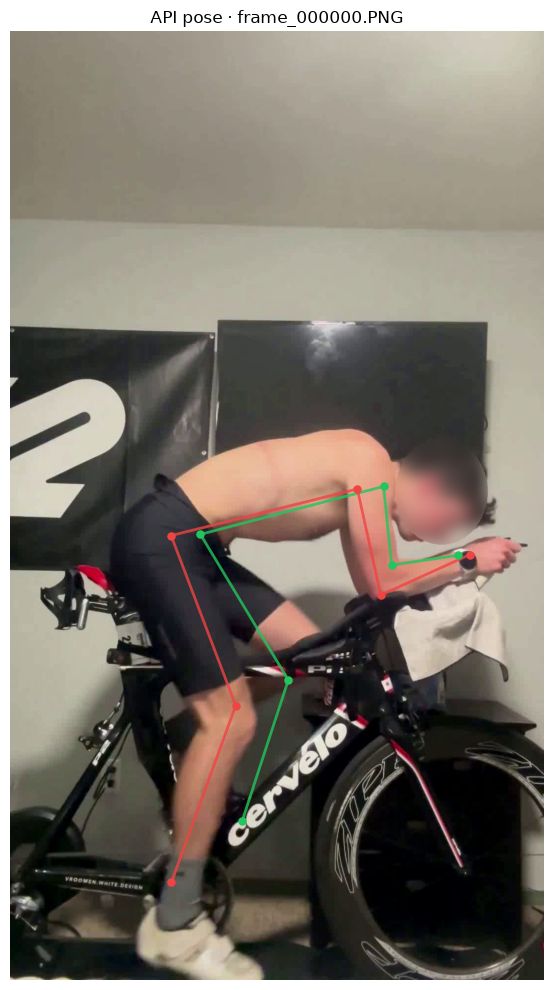

In [ ]:
def plot_api_pose(frame_row: pd.Series, title: str) -> None:
    image = Image.open(frame_row["image_path"])
    figure, axis = plt.subplots(figsize=(7, 10))
    axis.imshow(image)
    colors = {"left": "#22c55e", "right": "#ef4444"}
    segments = [
        ("shoulder", "elbow"), ("elbow", "wrist"),
        ("shoulder", "hip"), ("hip", "knee"), ("knee", "ankle"),
    ]
    for side in SIDES:
        color = colors[side]
        for landmark in ["shoulder", "elbow", "wrist", "hip", "knee", "ankle"]:
            x = frame_row.get(f"{side}_{landmark}_x")
            y = frame_row.get(f"{side}_{landmark}_y")
            if pd.notna(x) and pd.notna(y):
                axis.scatter(x, y, s=26, color=color, zorder=3)
        for first, second in segments:
            x1, y1 = frame_row.get(f"{side}_{first}_x"), frame_row.get(f"{side}_{first}_y")
            x2, y2 = frame_row.get(f"{side}_{second}_x"), frame_row.get(f"{side}_{second}_y")
            if pd.notna(x1) and pd.notna(x2):
                axis.plot([x1, x2], [y1, y2], color=color, linewidth=2, alpha=0.8, zorder=2)
    axis.set_title(title)
    axis.axis("off")
    plt.tight_layout()


def api_vs_annotation(annotated_row: pd.Series, api_row: pd.Series) -> pd.DataFrame:
    """Compara ángulos rodilla/cadera/codo entre anotación y API (tobillo no aplica)."""
    specs = {
        "knee_angle": ("hip", "knee", "ankle"),
        "hip_angle": ("shoulder", "hip", "knee"),
        "elbow_angle": ("shoulder", "elbow", "wrist"),
    }
    rows = []
    for side in SIDES:
        for metric, (first, vertex, last) in specs.items():
            try:
                annotated = angle_at(annotated_row, side, first, vertex, last)
            except (KeyError, TypeError):
                annotated = np.nan
            try:
                predicted = angle_at(api_row, side, first, vertex, last)
            except (KeyError, TypeError):
                predicted = np.nan
            rows.append({
                "side": side, "metric": metric,
                "annotation_deg": round(annotated, 1) if pd.notna(annotated) else None,
                "api_deg": round(predicted, 1) if pd.notna(predicted) else None,
                "abs_error_deg": round(abs(annotated - predicted), 1)
                if pd.notna(annotated) and pd.notna(predicted) else None,
            })
    return pd.DataFrame(rows)


try:
    api_row = predict_pose_api(selected_row["image_path"])
    print(f"Inferencia OK sobre {selected_row['image_path'].name}")
    plot_api_pose(api_row, f"API pose · {selected_row['image_path'].name}")
    comparison = api_vs_annotation(selected_row, api_row)
    display(comparison)
except RuntimeError as config_error:
    print(config_error)
except requests.HTTPError as http_error:
    print(f"Error HTTP de la API: {http_error} · revisa endpoint, clave y estado del deployment.")


## 10. Inferencia local con MediaPipe Pose (Tasks API)

MediaPipe Pose corre **en local, sin API ni claves**, y devuelve **33 landmarks**
que incluyen `foot_index` y `heel`. Eso encaja con el esquema de la notebook y, a
diferencia de la API COCO-17, permite calcular también el **ángulo de tobillo**.

El build actual de `mediapipe` ya no expone la API antigua `mp.solutions.pose`; se
usa la **Tasks API** (`PoseLandmarker`) con un modelo `.task` descargado a
`models/pose_landmarker_full.task`:

```bash
mkdir -p models
curl -sSL -o models/pose_landmarker_full.task \
  https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/latest/pose_landmarker_full.task
```

- Coordenadas normalizadas `[0, 1]` → se multiplican por ancho/alto de la imagen.
- Cada landmark trae `visibility`; lo usamos como proxy de oclusión.
- Comparamos la pose de MediaPipe contra la anotación manual del mismo frame.


In [3]:
import os
import subprocess
import sys

# Índices BlazePose (33) -> (lado, landmark) del esquema de la notebook.
MEDIAPIPE_TO_LANDMARK = {
    11: ("left", "shoulder"), 12: ("right", "shoulder"),
    13: ("left", "elbow"), 14: ("right", "elbow"),
    15: ("left", "wrist"), 16: ("right", "wrist"),
    23: ("left", "hip"), 24: ("right", "hip"),
    25: ("left", "knee"), 26: ("right", "knee"),
    27: ("left", "ankle"), 28: ("right", "ankle"),
    31: ("left", "foot_index"), 32: ("right", "foot_index"),
}

POSE_MODEL_PATH = PROJECT_ROOT / "models" / "pose_landmarker_full.task"
MEDIAPIPE_SCRIPT = PROJECT_ROOT / "scripts" / "mediapipe_infer.py"
# El build 1.0.1 de mediapipe aborta con Metal en macOS/Py3.13. Para obtener
# resultados, apunta MEDIAPIPE_PYTHON a un intérprete con mediapipe funcional
# (p. ej. un venv Python 3.12 con mediapipe==0.10.x). Por defecto usa el actual.
MEDIAPIPE_PYTHON = os.environ.get("MEDIAPIPE_PYTHON", sys.executable)


def predict_pose_mediapipe(image_path: Path, min_visibility: float = 0.5) -> pd.Series:
    """Ejecuta MediaPipe en un subproceso (kernel-safe) y devuelve una fila para angle_at."""
    completed = subprocess.run(
        [MEDIAPIPE_PYTHON, str(MEDIAPIPE_SCRIPT), str(POSE_MODEL_PATH), str(image_path), "0.5"],
        capture_output=True,
        text=True,
    )
    if completed.returncode != 0:
        raise RuntimeError(
            f"MediaPipe falló (código {completed.returncode}). Probablemente el build "
            f"aborta con Metal en este intérprete. Usa un venv Python 3.12 con mediapipe "
            f"0.10.x y expórtalo como MEDIAPIPE_PYTHON.\nstderr: {completed.stderr.strip()[-500:]}"
        )
    payload = json.loads(completed.stdout)
    if not payload["landmarks"]:
        raise ValueError(f"MediaPipe no detectó pose en {image_path.name}")

    width, height = payload["width"], payload["height"]
    row: dict[str, Any] = {"image_path": image_path, "source": "mediapipe"}
    for index, (side, landmark) in MEDIAPIPE_TO_LANDMARK.items():
        point = payload["landmarks"][index]
        low_visibility = point["visibility"] < min_visibility
        row[f"{side}_{landmark}_x"] = point["x"] * width
        row[f"{side}_{landmark}_y"] = point["y"] * height
        row[f"{side}_{landmark}_visibility"] = point["visibility"]
        row[f"{side}_{landmark}_occluded"] = low_visibility
        row[f"{side}_{landmark}_outside"] = low_visibility
    return pd.Series(row)


print("Intérprete MediaPipe:", MEDIAPIPE_PYTHON)
print("Script:", MEDIAPIPE_SCRIPT.name, "· existe:", MEDIAPIPE_SCRIPT.exists())
print("Modelo:", POSE_MODEL_PATH.name, "· existe:", POSE_MODEL_PATH.exists())


Intérprete MediaPipe: /Users/pol.serra/src-out/bikeFit/.venv/bin/python
Script: mediapipe_infer.py · existe: True
Modelo: pose_landmarker_full.task · existe: True


In [4]:
def plot_mediapipe_pose(frame_row: pd.Series, title: str) -> None:
    image = Image.open(frame_row["image_path"])
    figure, axis = plt.subplots(figsize=(7, 10))
    axis.imshow(image)
    colors = {"left": "#22c55e", "right": "#ef4444"}
    segments = [
        ("shoulder", "elbow"), ("elbow", "wrist"),
        ("shoulder", "hip"), ("hip", "knee"),
        ("knee", "ankle"), ("ankle", "foot_index"),
    ]
    for side in SIDES:
        color = colors[side]
        for landmark in ["shoulder", "elbow", "wrist", "hip", "knee", "ankle", "foot_index"]:
            x = frame_row.get(f"{side}_{landmark}_x")
            y = frame_row.get(f"{side}_{landmark}_y")
            if pd.notna(x) and pd.notna(y):
                axis.scatter(x, y, s=26, color=color, zorder=3)
        for first, second in segments:
            x1, y1 = frame_row.get(f"{side}_{first}_x"), frame_row.get(f"{side}_{first}_y")
            x2, y2 = frame_row.get(f"{side}_{second}_x"), frame_row.get(f"{side}_{second}_y")
            if pd.notna(x1) and pd.notna(x2):
                axis.plot([x1, x2], [y1, y2], color=color, linewidth=2, alpha=0.8, zorder=2)
    axis.set_title(title)
    axis.axis("off")
    plt.tight_layout()


def mediapipe_vs_annotation(annotated_row: pd.Series, predicted_row: pd.Series) -> pd.DataFrame:
    """Compara ángulos (incluye tobillo, disponible gracias a foot_index)."""
    specs = {
        "knee_angle": ("hip", "knee", "ankle"),
        "hip_angle": ("shoulder", "hip", "knee"),
        "ankle_angle": ("knee", "ankle", "foot_index"),
        "elbow_angle": ("shoulder", "elbow", "wrist"),
    }
    rows = []
    for side in SIDES:
        for metric, (first, vertex, last) in specs.items():
            try:
                annotated = angle_at(annotated_row, side, first, vertex, last)
            except (KeyError, TypeError):
                annotated = np.nan
            try:
                predicted = angle_at(predicted_row, side, first, vertex, last)
            except (KeyError, TypeError):
                predicted = np.nan
            rows.append({
                "side": side, "metric": metric,
                "annotation_deg": round(annotated, 1) if pd.notna(annotated) else None,
                "mediapipe_deg": round(predicted, 1) if pd.notna(predicted) else None,
                "abs_error_deg": round(abs(annotated - predicted), 1)
                if pd.notna(annotated) and pd.notna(predicted) else None,
            })
    return pd.DataFrame(rows)


try:
    mediapipe_row = predict_pose_mediapipe(selected_row["image_path"])
    print(f"Inferencia MediaPipe OK sobre {selected_row['image_path'].name}")
    plot_mediapipe_pose(mediapipe_row, f"MediaPipe · {selected_row['image_path'].name}")
    display(mediapipe_vs_annotation(selected_row, mediapipe_row))
except (RuntimeError, ValueError) as mediapipe_error:
    print(mediapipe_error)


NameError: name 'selected_row' is not defined